# Introdução às Redes Neurais e Deep Learning

## O Perceptron Multicamada - Continuação

### Versão adaptada da classe `NeuralNetwork` para classificação em problemas com Múltiplas Classes

Nesta aula o objetivo é estudar uma adaptação de nossa Rede Neural didática para reconhecimento de imagens de algarismos manuscritos  do conjunto de dados MNIST. Essa base de dados é popularmente utilizada como *benchmark* em aprendizado de máquina e aprendizado profundo, consistindo de 60000 imagens de treino e 10000 imagens de teste com resolução de 28x28 (784 características) pixels cada uma. 

Formato original: (60000, 28, 28)


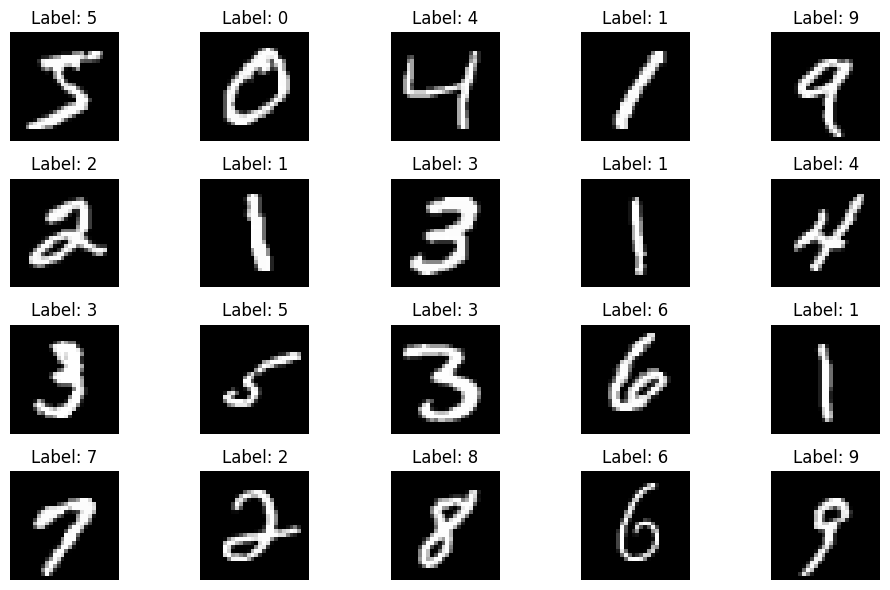

In [2]:
import numpy as np
import matplotlib.pyplot as plt
#Loading
from keras.datasets import mnist
(X_train, y_train), (X_test, y_test) = mnist.load_data()
print("Formato original:", X_train.shape)

# Normalização para [0, 1]
X_train = X_train.astype(np.float64) / 255.0
X_test = X_test.astype(np.float64) / 255.0

fig, axes = plt.subplots(4, 5, figsize=(10, 6))
for i, ax in enumerate(axes.flat):
    ax.imshow(X_train[i], cmap='gray')
    ax.set_title(f'Label: {y_train[i]}')
    ax.axis('off')

plt.tight_layout()
plt.show()

Algumas adições foram implementadas ao código original. São elas:
* **Função de ativação Softmax**
  
O classificador neural implementado deverá possuir 10 neurônios na camada de saída, cada um correspondendo a uma das classes que por sua vez corresponde à um dos algarismos entre 0 e 10.

Cada rótulo associado à um conjunto de pixels de entrada indica o algarismo *n* corretamente representado pela imagem. Este rótulo é transformado em um *Array* de 10 elementos associados à 10 neurônios, onde o n-ésimo neurônio tem seu rótulo igual a 1, enquanto todos os outros são nulos. Esta adequação dos rótulos de entrada é feita pela função de codificação *one-hot*. 

Para um problema de classificação binária, a função de ativação Sigmoid aplicada ao neurônio de saída é  
$$\hat{y}=\frac{1}{1+e^{-z}},$$
sendo que $\hat{y} \in [0,1]$. Interpretamos este resultado como um modelo logístico da probabilidade de *y* ser 1, e portanto a probabilidade de *y* ser 0 se torna $1-\hat{y}$, ou seja, a soma das probabilidades é unitária. Aplicando à um modelo com múltiplas saídas, devemos calcular uma função de distribuição de probabilidades na qual $\hat{y}_i \in [0,1]$ e $\sum_i \hat{y}_i=1$. Isto é realizado com a função de ativação Softmax: em um problema com 10 classes a entrada da função de ativação será um vetor de dimensão igual ao número de categorias:
$$\bf{z}=\begin{bmatrix}z_{o1}\\z_{o2}\\\vdots\\z_{o10}\end{bmatrix},$$ 
daí,
$$\hat{y}_i=\frac{e^{z_i}}{\sum_j e^{z_j} } \forall\; 0\le i\le9$$


* **Função de perdas *Categorical Cross-Entropy***

  A função de perdas *Cross-Entropy* é definida como
  $$L=-\sum_i y_i\;\ln(\hat{y}_i)$$
  Para classificação binária as probabilidades seriam *y* e 1-*y*, de forma que teríamos a função *log loss*:
  $$L=-y\;\ln(\hat{y})+(1-y)\;\ln(1-\hat{y})$$
 Agora, vamos ver como a função logarítmica acima funciona no uso da classificação binária, ou seja, quando o valor de saída real é 1 ou 0. Temos dois casos:

* Se $y=1$, $L=-\ln(\hat{y})$: Neste caso, quanto menor $\hat{y}$, mais penalizado é o modelo com uma função custo maior. 

* Se $y=0$, $L=-\ln(1-\hat{y})$: quanto maior $\hat{y}$ mais penalizado é o modelo com maior valor da função custo.

  Finalmente, a derivada da função custo de entropia cruzada associada com a função de ativação Softmax relativa as variáveis $z_i$ é obtida abaixo:

  Seja $L=-\sum_i y_i \ln(\frac{e^{z_i}}{\sum_j e^{z_j}})$. Por simplicidade, vamos considerar sem perda de generalidade o caso binário. Desta forma teremos:

  $$L=-y_1\ln\frac{e^{z_1}}{e^{z_1}+e^{z_2}}-y_2\ln\frac{e^{z_2}}{e^{z_1}+e^{z_2}}=-y_1\ln(e^{z_1})+y_1\ln(e^{z_1}+e^{z_2})-y_2\ln(e^{z_2})+y_2\ln(e^{z_1}+e^{z_2})$$

  $$L=-y_1z_1+y_1\ln(e^{z_1}+e^{z_2})-y_2z_2+y_2\ln(e^{z_1}+e^{z_2}).$$

  Assim,

  $$\frac{\partial L}{\partial z_1}=-y_1+y_1\frac{e^{z_1}}{e^{z_1}+e^{z_2}}+y_2\frac{e^{z_1}}{e^{z_1}+e^{z_2}}=\hat{y}_1(y_1+y_2)-y_1,\,$$

  $$\frac{\partial L}{\partial z_2}=\hat{y}_2(y_1+y_2)-y_2,\; \text{e}$$

  $$\frac{\partial L}{\partial z_i}=\hat{y}_i\sum_j y_j-y_i=\hat{y}_i-y_i$$

  para o caso geral. A última igualdade se deve ao fato que a soma das saídas possíveis é um. 

* **Codificação *one-hot***

  A codificação *One-Hot* é uma técnica de pré-processamento de dados utilizada para converter dados categóricos em um formato numérico que modelos de aprendizado de máquina possam compreender. Ele cria linhas binárias separadas para cada categoria, onde 1 representa a presença de uma categoria e 0 representa a sua ausência. No código,

  ```python
    def one_hot(self, y, n_output):

        y = np.asarray(y).ravel().astype(int)
        y_hot = np.zeros((n_output, len(y)))
        y_hot[y, np.arange(len(y))] = 1

        return y_hot 
* **SGD com mini-batches**

Na versão anterior os gradientes eram calculados com o algorítmo puro dos Gradientes Descendentes. Por outro lado,  o arquivo MNIST possui 60000 imagesn de treino, consequentemente o cálculo simultâneo de todos os gradientes é desnecessáriamente pesado em termos de eforço computacional.

In [3]:
import numpy as np

# Xavier Normalized Initialization
def initWeights(layerOut_size, layerIn_size):
    return np.random.uniform(-1, 1, (layerOut_size, layerIn_size)) * np.sqrt(6 / (layerIn_size + layerOut_size))

class NeuralNetwork:

    """Os dados devem ter formato:
       X[n_input, n_amostras]
       y[n_output, n_amostras]
    """

    def __init__(self, hidden_activation, output_activation, loss,
                 n_input, n_hidden, n_output):

        # Armazena o número de neurônios em cada camada
        self.n_input = n_input
        self.n_hidden = n_hidden
        self.n_output = n_output
        
        # Armazena as funções de ativação para cada camada e a função custo
        self.hidden_activation = hidden_activation
        self.output_activation = output_activation
        self.loss = loss

        # Inicializa as matrizes de pesos
        np.random.seed(42)
        self.w_h = initWeights(n_hidden, n_input)
        self.w_o = initWeights(n_output, n_hidden)
        self.bias_h = np.zeros((n_hidden, 1))
        self.bias_o = np.zeros((n_output, 1))

        # Evolução da função custo
        self.loss_history = []

    def activation_function(self, f_activ, x):

        if f_activ == 'linear':
            return x
        if f_activ == 'sigmoid':
            return 1 / (1 + np.exp(-np.clip(x, -500, 500)))
        if f_activ == 'tanh':
            return np.tanh(x)
        if f_activ == 'relu':
            return np.maximum(0, x)
        if f_activ == 'softmax':
            exp_x = np.exp(x - np.max(x, axis=0, keepdims=True))
            return exp_x / np.sum(exp_x, axis=0, keepdims=True)

        raise ValueError("Ativação desconhecida")

    def deriv_activ_function(self, f_activ, x):

        if f_activ == 'linear':
            return np.ones_like(x)
        if f_activ == 'sigmoid':
            fx = self.activation_function(f_activ, x)
            return fx * (1 - fx)
        if f_activ == 'tanh':
            fx = np.tanh(x)
            return 1 - fx**2
        if f_activ == 'relu':
            return (x > 0).astype(np.float64)

        # A derivada da softmax é uma Jacobiana.
        # Para softmax + categorical_crossentropy,
        # calculamos diretamente dL/dZo no backward.

        raise ValueError("Derivada não implementada")

    def compute_loss(self, y, y_hat):

        eps = 1e-15
        y_hat = np.clip(y_hat, eps, 1 - eps)

        if self.loss == 'categorical_crossentropy':
            # Soma sobre as classes e média das amostras
            return -np.mean(np.sum(y * np.log(y_hat), axis=0))
        if self.loss == 'logloss':
            return -np.mean( y * np.log(y_hat) +(1 - y) * np.log(1 - y_hat))
        if self.loss == 'mse':
            return np.mean((y - y_hat)**2)

        raise ValueError("Função de perda desconhecida")

    def deriv_loss(self, y, y_hat):

        eps = 1e-15
        y_hat = np.clip(y_hat, eps, 1 - eps)

        # Número total de elementos, consistente
        # com np.mean() usado em mse e logloss
        n = y.size

        if self.loss == 'logloss':
            return (y_hat - y) / (n * y_hat * (1 - y_hat))

        if self.loss == 'mse':
            return 2 * (y_hat - y) / n

        raise ValueError(
            "Para categorical_crossentropy com softmax, "
            "usar diretamente dL/dZo"
        )

    def one_hot(self, y, n_output):

        y = np.asarray(y).ravel().astype(int)
        y_hot = np.zeros((n_output, len(y)))
        y_hot[y, np.arange(len(y))] = 1

        return y_hot

    def forward_propagation(self, X):

        z_h = np.dot(self.w_h,X)+ self.bias_h
        output_h = self.activation_function(self.hidden_activation, z_h)
        z_o = np.dot(self.w_o,output_h)+ self.bias_o
        y_hat = self.activation_function(self.output_activation, z_o)

        return z_h, z_o, output_h, y_hat
    

    def backward_propagation( self, X, y, z_h, z_o, output_h, y_hat):

        m = X.shape[1]

        # Camada de saída
        # =========================
        if (self.output_activation == 'softmax' and
                self.loss == 'categorical_crossentropy'):

            # Derivada conjunta da softmax e da perda dL/dZo
            dz_o = (y_hat - y) / m
        else:
            #dL/dYhat
            dYhat = self.deriv_loss(y, y_hat)
            #dL/dZo
            dz_o = dYhat * self.deriv_activ_function(self.output_activation, z_o)
        #dL/dWo
        dw_o = np.dot(dz_o,output_h.T)
        #dL/d_bias_o
        db_o = np.sum(dz_o, axis=1, keepdims=True)

        # Camada oculta
        # =========================
        #dL/dZh
        dz_h = np.dot(self.w_o.T,dz_o)*(self.deriv_activ_function(self.hidden_activation,z_h))
        #dL/dWh
        dw_h = np.dot(dz_h,X.T)
        #dL/d_bias_h
        db_h = np.sum(dz_h, axis=1, keepdims=True)

        return dw_h, dw_o, db_h, db_o

    def train(self, X, y, epochs=20, learning_rate=0.1,batch_size=128):

        m = X.shape[1]

        for epoch in range(epochs):

            # Embaralha as amostras
            indices = np.random.permutation(m)

            for start in range(0, m, batch_size):

                batch_idx = indices[start:start + batch_size]

                X_batch = X[:, batch_idx]
                y_batch = y[:, batch_idx]

                # Forward propagation
                z_h, z_o, output_h, y_hat = self.forward_propagation(X_batch)
                # Recupera o vetor gradiente=[dw_o,db_o,dw_h,db_h]
                dw_h, dw_o, db_h, db_o=self.backward_propagation(X_batch, y_batch,z_h, 
                                                                 z_o, output_h, y_hat)

                # Atualização dos parâmetros
                self.w_h -= learning_rate * dw_h
                self.w_o -= learning_rate * dw_o

                self.bias_h -= learning_rate * db_h
                self.bias_o -= learning_rate * db_o

            # Perdas
            _, _, _, y_hat = self.forward_propagation(X)
            cost = self.compute_loss(y, y_hat)
            self.loss_history.append(cost)

            accuracy = np.mean(np.argmax(y_hat, axis=0) == np.argmax(y, axis=0) )

            print(
                f"Epoch {epoch+1:3d}/{epochs} - "
                f"Loss: {cost:.4f} - "
                f"Accuracy: {accuracy:.4f}"
            )

    def predict(self, X):
        _, _, _, y_hat = self.forward_propagation(X)
        return y_hat

    def predict_classes(self, X):
        return np.argmax(self.predict(X), axis=0)
    

#### Pre-processamento dos dados da base MNIST e definição do modelo

In [4]:
model = NeuralNetwork(hidden_activation='relu', output_activation='softmax', loss='categorical_crossentropy',
        n_input=784,n_hidden=128,n_output=10)


# Cada imagem 28x28 passa a ter 784 elementos
# Cada coluna representa uma imagem
X_train = X_train.reshape(-1, 784).T
X_test = X_test.reshape(-1, 784).T

# One-hot encoding
Y_train = model.one_hot(y_train, 10)
Y_test = model.one_hot(y_test, 10)

print("X_train:", X_train.shape)
print("Y_train:", Y_train.shape)
print("X_test:", X_test.shape)
print("Y_test:", Y_test.shape)


X_train: (784, 60000)
Y_train: (10, 60000)
X_test: (784, 10000)
Y_test: (10, 10000)


#### Treinamento da rede

In [5]:
model.train(X_train,Y_train,epochs=20,learning_rate=0.1, batch_size=128)

Epoch   1/20 - Loss: 0.2839 - Accuracy: 0.9208
Epoch   2/20 - Loss: 0.2225 - Accuracy: 0.9371
Epoch   3/20 - Loss: 0.1831 - Accuracy: 0.9488
Epoch   4/20 - Loss: 0.1567 - Accuracy: 0.9569
Epoch   5/20 - Loss: 0.1375 - Accuracy: 0.9620
Epoch   6/20 - Loss: 0.1226 - Accuracy: 0.9666
Epoch   7/20 - Loss: 0.1095 - Accuracy: 0.9702
Epoch   8/20 - Loss: 0.1015 - Accuracy: 0.9724
Epoch   9/20 - Loss: 0.0921 - Accuracy: 0.9755
Epoch  10/20 - Loss: 0.0845 - Accuracy: 0.9774
Epoch  11/20 - Loss: 0.0797 - Accuracy: 0.9782
Epoch  12/20 - Loss: 0.0753 - Accuracy: 0.9801
Epoch  13/20 - Loss: 0.0680 - Accuracy: 0.9819
Epoch  14/20 - Loss: 0.0658 - Accuracy: 0.9819
Epoch  15/20 - Loss: 0.0609 - Accuracy: 0.9835
Epoch  16/20 - Loss: 0.0572 - Accuracy: 0.9851
Epoch  17/20 - Loss: 0.0547 - Accuracy: 0.9856
Epoch  18/20 - Loss: 0.0526 - Accuracy: 0.9862
Epoch  19/20 - Loss: 0.0490 - Accuracy: 0.9873
Epoch  20/20 - Loss: 0.0462 - Accuracy: 0.9886


#### Predições e evolução da função de perda

Acurácia no teste: 0.9763


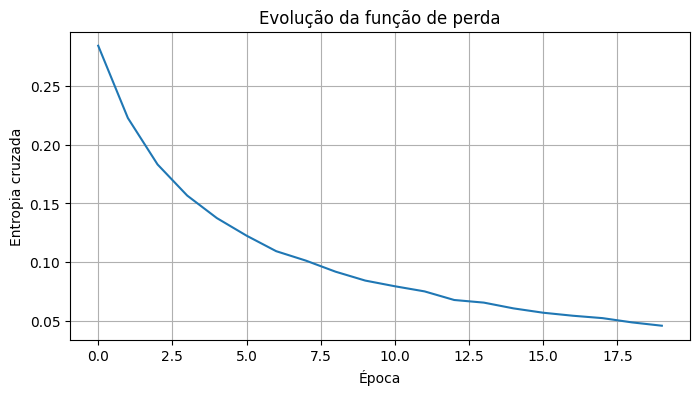

In [6]:
# Predições
y_pred = model.predict_classes(X_test)

# Acurácia
accuracy = np.mean(y_pred == y_test)

print(f"Acurácia no teste: {accuracy:.4f}")

# Evolução da função de perda
plt.figure(figsize=(8, 4))
plt.plot(model.loss_history)
plt.xlabel("Época")
plt.ylabel("Entropia cruzada")
plt.title("Evolução da função de perda")
plt.grid(True)
plt.show()


#### Visualização de classificações

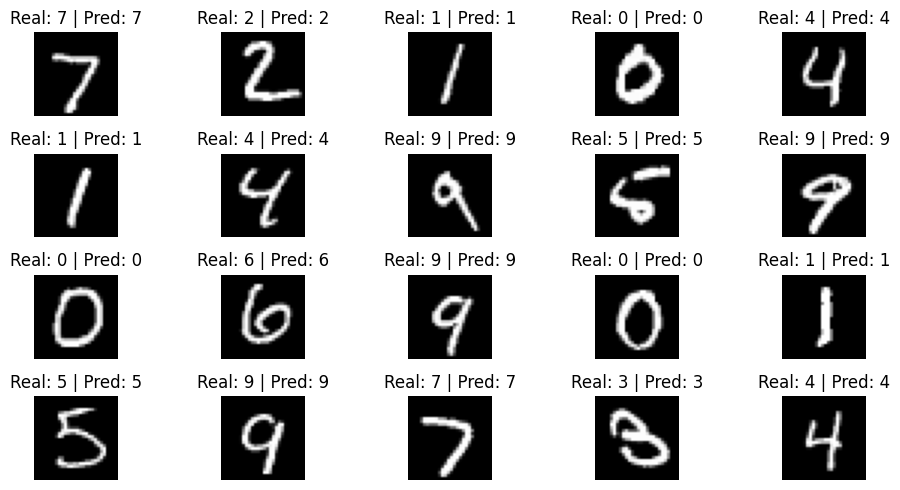

In [7]:
fig, axes = plt.subplots(4, 5, figsize=(10, 5))

for i, ax in enumerate(axes.flat):
    imagem = X_test[:, i].reshape(28, 28)

    ax.imshow(imagem, cmap='gray')
    ax.set_title(
        f"Real: {y_test[i]} | Pred: {y_pred[i]}"
    )
    ax.axis('off')

plt.tight_layout()
plt.show()


#### Visualização de classificações incorretas

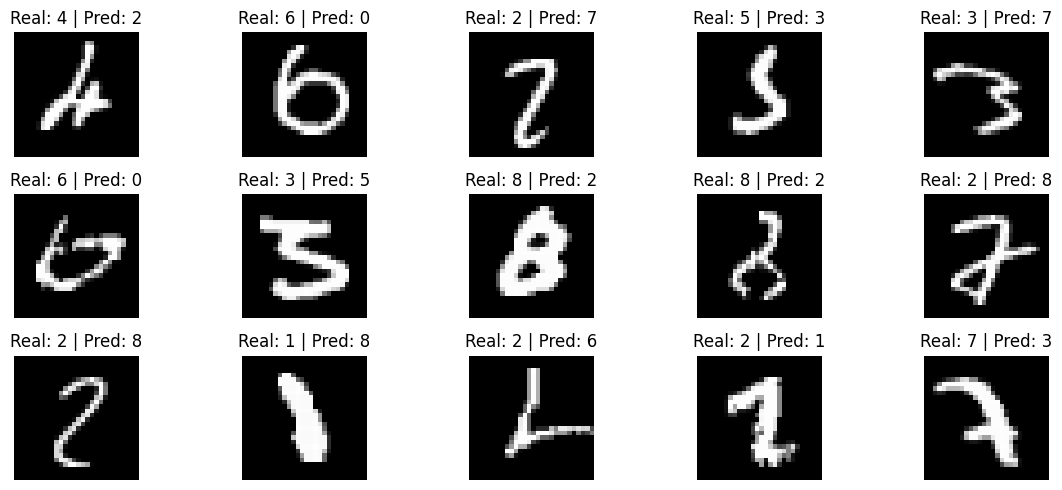

In [8]:
# Identifica as classificações incorretas
erros = np.where(y_pred != y_test)[0]

fig, axes = plt.subplots(3, 5, figsize=(12, 5))

for i, ax in enumerate(axes.flat):
    idx = erros[i]

    imagem = X_test[:, idx].reshape(28, 28)

    ax.imshow(imagem, cmap='gray')
    ax.set_title(
        f"Real: {y_test[idx]} | Pred: {y_pred[idx]}"
    )
    ax.axis('off')

plt.tight_layout()
plt.show()